<a href="https://colab.research.google.com/github/vestrada-data/Radar_permanencia_estudiantil/blob/main/Radar_de_Permanecia_Estudiantil.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Radar de Permanencia Estudiantil: alerta temprana de deserción**


**🎯 Objetivo:**
La identificación tempranamente de estudiantes en riesgo de deserción permite una intervención proactiva y una mejor focalización de los esfuerzos de atracción. Ayudando al estudiante, a la familia y a la Universidad.

¿A qué estudiantes hay que contactar, en qué semestre y con qué tipo de apoyo , para evitar que abandonen, cuando solo se puede intervenir a una parte de ellos?

- Fuente del proyecto:  
Dataset: academic_survival_longitudinal.csv (Kaggle: Student Retention & Academic Performance Data).
- Link a la fuente original : https://www.kaggle.com/datasets/razanihababdellatif/student-retention-and-academic-performance-data

- Stack: Python (Jupyter) para limpieza, EDA y modelo → Power BI para análisis y visualización.


## 🔹 Cargar y revisión de estructura de datos

🎯 Familiarizarse con la
 de los datasets del negocio antes de analizarlos.

In [1]:
!pip -q install kagglehub
import kagglehub

path = kagglehub.dataset_download(
    "razanihababdellatif/student-retention-and-academic-performance-data"
)

print("Dataset descargado en:", path)

Using Colab cache for faster access to the 'student-retention-and-academic-performance-data' dataset.
Dataset descargado en: /kaggle/input/student-retention-and-academic-performance-data


In [2]:
#Importanto librerias
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Importar libreras para el modelado

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

data_dir = Path(
    '/kaggle/input/student-retention-and-academic-performance-data'
)

csv_files = list(data_dir.rglob('*.csv'))

if not csv_files:
    raise FileNotFoundError("No se encontró ningún archivo CSV.")

df = pd.read_csv(csv_files[0])
df_completo = pd.read_csv(csv_files[0])

print("Datos cargados correctamente")
print("Filas y columnas:", df.shape)

display(df.head())

Datos cargados correctamente
Filas y columnas: (79239, 22)


,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Emergency_Expense,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored
0,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,1,...,0.0,2.85,85.8,67.0,0,0,1.7,0,Enrolled,0
1,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,2,...,0.0,2.73,81.0,89.0,1,0,3.1,0,Enrolled,0
2,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,3,...,0.0,2.60,78.3,60.0,0,2,3.0,0,Enrolled,0
3,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,4,...,0.0,2.34,77.2,59.0,2,3,5.1,0,Enrolled,0
4,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,5,...,0.0,1.90,79.3,53.0,1,2,3.6,0,Enrolled,1


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79239 entries, 0 to 79238
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Student_ID               79239 non-null  object 
 1   Age                      79239 non-null  int64  
 2   Gender                   79239 non-null  object 
 3   First_Generation         79239 non-null  int64  
 4   Family_Income            75635 non-null  float64
 5   Household_Size           79239 non-null  int64  
 6   Housing_Status           79239 non-null  object 
 7   Scholarship              79239 non-null  int64  
 8   Tuition_Base             79239 non-null  int64  
 9   Semester                 79239 non-null  int64  
 10  Course_Load              79239 non-null  int64  
 11  Work_Hours               79239 non-null  float64
 12  Emergency_Expense        79239 non-null  float64
 13  Sem_GPA                  79239 non-null  float64
 14  Attendance            

In [4]:
# Revisamos valores nulos en cada columna
missing_values = df.isnull().sum()
print('\nMissing values in each column:')
print(missing_values[missing_values > 0])


Missing values in each column:
Family_Income    3604
LMS_Logins        867
dtype: int64


# Revisión y calidad de datos
🎯 En esta sección revisaremos las columnas del dataset, y realizaremos la limpieza y normalización de datos.
Verificando datos nulos, valores faltantes y transormando datos si es neceario.

In [5]:
#Copiamos dataset para trabajar sin modificar original
df=df.copy()

print(f'Edad mínima registrada: {df['Age'].min()}')
print(f'Edad máxima registrada: {df['Age'].max()}')

Edad mínima registrada: 17
Edad máxima registrada: 37


In [6]:
# Revisamos Valores de genero
print(f"Genero:\n{df['Gender'].value_counts()}")

Genero:
Gender
Female               38035
Male                 36556
Other                 1125
female                 875
male                   764
M                      739
F                      716
Prefer not to say      429
Name: count, dtype: int64


In [7]:
# Estandarizar Gender y validamos camibos

# Datos sucios
s = pd.Series(["f", "male", "female", "m", "other"])

# Aplicando tu mapa
df['Gender'] = df['Gender'].str.strip()
df['Gender'] = s.map({
    "f": "Female", "female": "Female",
    "m": "Male", "male": "Male",
    "other": "Other", "prefer not to say": "Prefer not to say"
})

print(df['Gender'].value_counts(dropna=False))

Gender
NaN       79234
Female        2
Male          2
Other         1
Name: count, dtype: int64


In [8]:
#Revisión de valores negativos, ceros invalidos o valores fuera de rango
columns = {'Tuition_Base', 'Family_Income','Scholarship', 'First_Generation','Household_Size', 'Semester', 'Course_Load', 'Work_Hours', 'Emergency_Expense', 'Sem_GPA','Attendance', 'Advising_Visits', 'LMS_Logins', 'Failed_Courses','Financial_Stress','Target_Dropout_Next_Sem'}

for i in columns:
    print(f"\n{i}:")
    print(df[i].value_counts(dropna=False))


LMS_Logins:
LMS_Logins
68.0     2488
64.0     2486
65.0     2479
69.0     2426
66.0     2410
         ... 
19.0        2
18.0        1
12.0        1
114.0       1
17.0        1
Name: count, Length: 105, dtype: int64

First_Generation:
First_Generation
0    53257
1    25982
Name: count, dtype: int64

Course_Load:
Course_Load
15    41604
12    18396
18    16124
9      1725
21     1390
Name: count, dtype: int64

Tuition_Base:
Tuition_Base
25000    32160
15000    31980
45000    15099
Name: count, dtype: int64

Scholarship:
Scholarship
0    57249
1    21990
Name: count, dtype: int64

Failed_Courses:
Failed_Courses
0    40551
1    27876
2     8870
3     1699
4      225
5       18
Name: count, dtype: int64

Attendance:
Attendance
84.8    575
84.2    571
85.4    560
84.5    560
84.4    559
       ... 
63.7      1
65.1      1
64.7      1
58.7      1
62.5      1
Name: count, Length: 366, dtype: int64

Emergency_Expense:
Emergency_Expense
0.0       72926
1520.0        9
3154.0        8
2616.0   

In [9]:
#revisión de registros duplicados
df.duplicated().sum()

np.int64(0)


- Se encontraron 3604 registros nulos correspondientes a Family_Income, que representan un 4.54%  del total de esos datos
- 867 regsitros de LMS_Logins que solo son un 1.09%
- Se detectó que el campo de generó estaba capturado de diferentes formas, por lo que fue formalizado quedando como 'Female' y 'Male'
- Al revisar los campos numericos no se localizaron valores negativos, ceros invalidos o valores fuera de rango que se consideraran para tener un trato particular.



# Análisis Exploratorio

🎯 En el siguiente paso analizaremos la información del dataset con respecto a diferentes factores como son métricas académicas, demográficas y financieras.

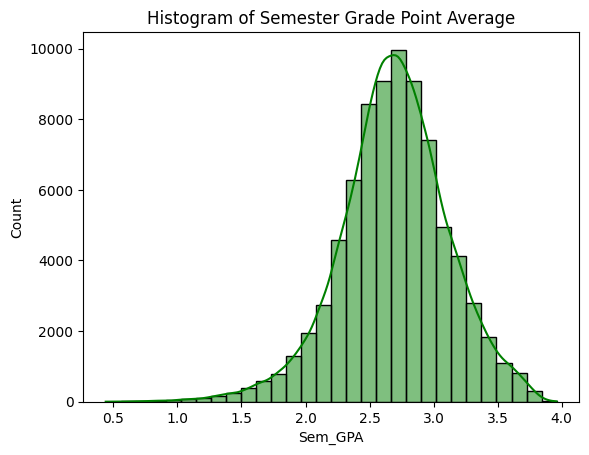

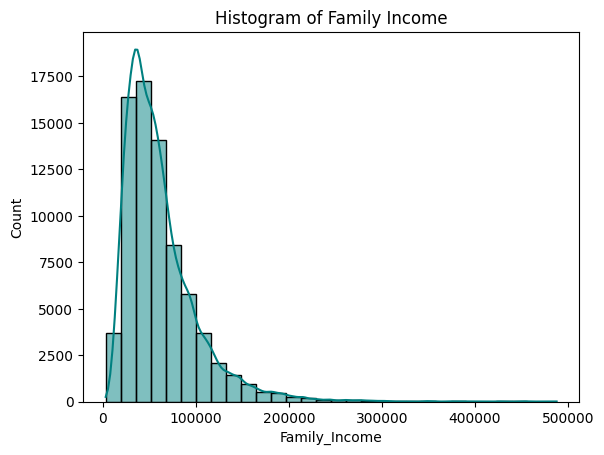

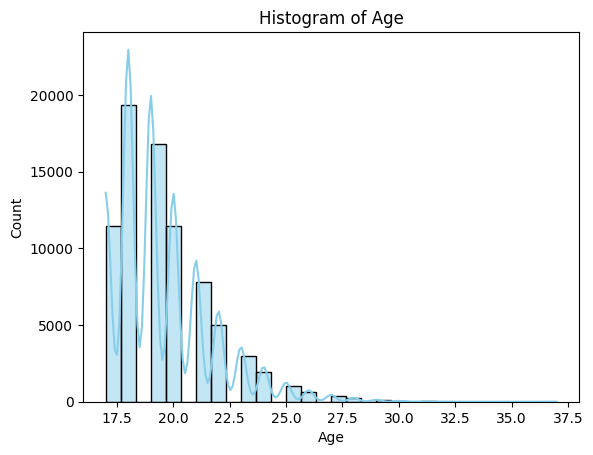

In [10]:
#Histogramas de métricas
plt.figure()
sns.histplot(df['Sem_GPA'].dropna(), kde=True, bins=30, color= 'green',  alpha=0.5)
plt.title(f'Histogram of Semester Grade Point Average')
plt.show()

#Semester Grade Point Average
plt.figure()
sns.histplot(df['Family_Income'].dropna(), kde=True, bins=30,   color='teal',alpha=0.5)
plt.title(f'Histogram of Family Income')
plt.show()

 #Histogramas de métricas
plt.figure()
sns.histplot(df['Age'].dropna(), kde=True, bins=30, color= 'skyblue',  alpha=0.5)
plt.title(f'Histogram of Age')
plt.show()




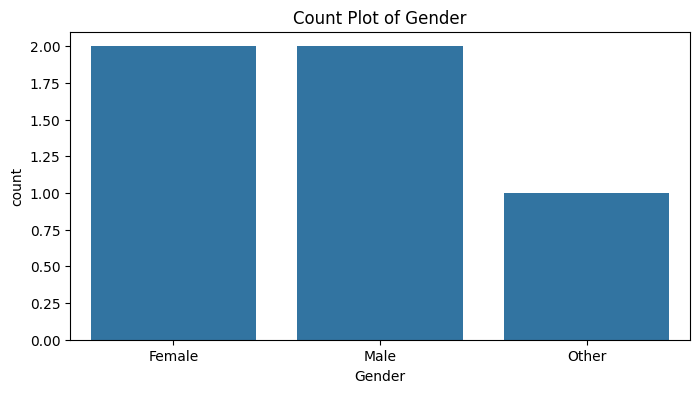

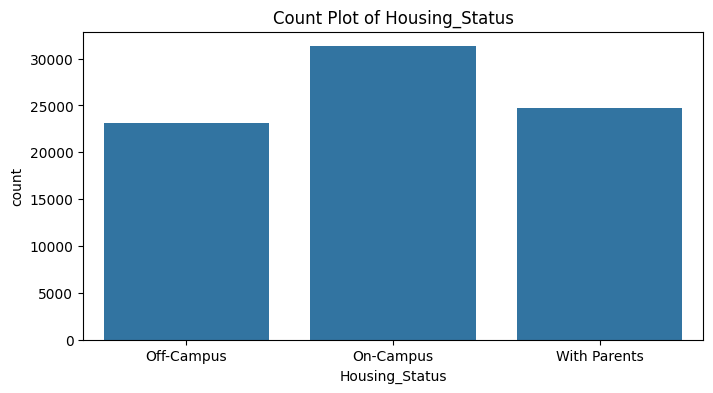

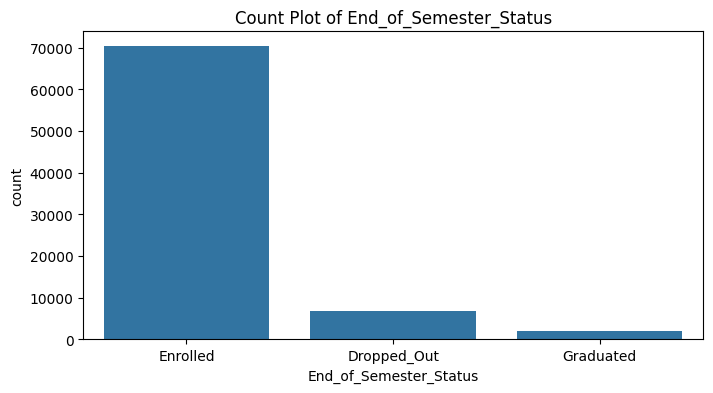

In [11]:
# Count plot for categorical variables
for col in ['Gender', 'Housing_Status', 'End_of_Semester_Status']:
    if col in df.columns:
        plt.figure(figsize=(8, 4))
        sns.countplot(x=col, data=df)
        plt.title(f'Count Plot of {col}')
        plt.show()


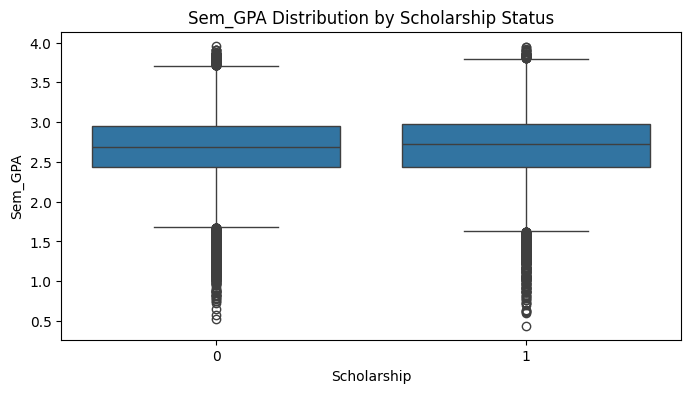

In [12]:
# Box plot for distribution of Sem_GPA across Scholarship status
if set(['Sem_GPA', 'Scholarship']).issubset(df.columns):
    plt.figure(figsize=(8, 4))
    sns.boxplot(x='Scholarship', y='Sem_GPA', data=df)
    plt.title('Sem_GPA Distribution by Scholarship Status')
    plt.show()

# Análisis Exploratorio

🎯 En el siguiente paso incluye la construcción y evaluación de predictores.

Utilizaré una regresión logística,  este es un modelo que calcula una probabilidad (un número entre 0 y 1) de que algo ocurra, a partir de varias características. Es decir,  la probabilidad de que un estudiante abandone después de este semestre, según su GPA, cursos reprobados, estrés financiero, beca, etcétera.

Cada variable suma o resta “puntos de riesgo”. El modelo asigna un peso a cada variable. Si el GPA es bajo, resta puntos de seguridad. Si hay más cursos reprobados o más estrés financiero, suma puntos de riesgo.

El objetivo es lograr una precisión de predicción razonable y utilizar métodos visuales, como la matriz de confusión y las curvas ROC, para evaluar el rendimiento del modelo.

In [13]:


from sklearn.preprocessing import OneHotEncoder, StandardScaler
# Para entrenar, el modelo necesita saber qué pasó.

# 1) Solo filas con valor conocido
 #La última fila de quien sigue inscrito todavía no tiene resultado, así que se excluye. Censored=1 (Inscritos)
df = df[df["Censored"] == 0]

# 2) Variables: incluimos algunos variables con base en intuición y EDA, sin End_of_Semester_Status ni Censored (fuga de información)
num = ["Age", "First_Generation", "Family_Income", "Household_Size", "Scholarship", "Tuition_Base", "Semester",
       "Course_Load", "Work_Hours", "Emergency_Expense", "Sem_GPA", "Attendance", "LMS_Logins",
       "Advising_Visits", "Failed_Courses", "Financial_Stress"]  # variables numéricas
cat = ["Gender", "Housing_Status"]   # variables de texto

# Prepareamos X y y
X = df[num + cat]  #son los datos que el modelo mira (GPA, reprobadas, estrés…).
y = df["Target_Dropout_Next_Sem"] # y es lo que debe aprender a predecir: coloca un 1 si abandonó y 0 si no.

print(X.shape)       # filas y columnas de X
print(X.head())      # primeras filas de X
print(y.value_counts())   # cuántos 0 y 1 hay en y



(68124, 18)
   Age  First_Generation  Family_Income  Household_Size  Scholarship  \
0   18                 0        15000.0               2            0   
1   18                 0        15000.0               2            0   
2   18                 0        15000.0               2            0   
3   18                 0        15000.0               2            0   
5   20                 1        80000.0               5            1   

   Tuition_Base  Semester  Course_Load  Work_Hours  Emergency_Expense  \
0         15000         1           15        18.4                0.0   
1         15000         2           15        23.1                0.0   
2         15000         3           15        19.1                0.0   
3         15000         4           15        26.5                0.0   
5         25000         1           12         0.1                0.0   

   Sem_GPA  Attendance  LMS_Logins  Advising_Visits  Failed_Courses  \
0     2.85        85.8        67.0           

In [14]:
# 3) #Se separa el 80% de los estudiantes para que el modelo aprenda y el 20% para examinarlo con datos que no vio
#Devuelve dos listas de posiciones de filas: tr (train) y te (test)
#el 20% de los estudiantes va a prueba y el 80% a entrenamiento.
#El número 42 es arbitrario
tr, te = next(GroupShuffleSplit(test_size=0.2, random_state=42).split(X, y, df["Student_ID"]))
#GroupShuffleSplit puede generar varios repartos distintos (por defecto 5). next() toma solo el primero, que es el que necesitamos.


# 4) Modelo: regresión logística -  probabilidad de abandono.
#StandardScaler - variables en una escala comparable
#OneHotEncoder: convierte categorías como género o vivienda en columnas de 0 y 1
prep = ColumnTransformer([
  ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
  ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])   # PREPARA
modelo = make_pipeline(prep, LogisticRegression(max_iter=1000))  #CREA EL MODELO

# X.iloc[tr]  -  datos para entrenar
# X.iloc[te]  -  datos para examinar al modelo
modelo.fit(X.iloc[tr], y.iloc[tr])   #ENTRENA


#Obtener archivo con alumnos con mayor posibilidad de abandono

final = df_completo.copy()

# 1) Probabilidad de abandono para todas las filas
final["risk_score"] = modelo.predict_proba(final[num + cat])[:, 1]   #devuelve la probabilidad de abandono de cada estudiante

# 2) Nivel de riesgo (Alto = 20% superior, Medio = siguiente 30%, Bajo = resto)
c50, c80 = np.quantile(final["risk_score"], [0.50, 0.80])  #pidiendo a NumPy que calcule dos valores numéricos que sirven de frontera (0.50 y 0.80)
final["risk_tier"] = np.where(final["risk_score"] >= c80, "Alto",
                      np.where(final["risk_score"] >= c50, "Medio", "Bajo"))

# 3) Marcar de dónde viene cada fila
ids_train = set(df["Student_ID"].iloc[tr]) #tr - Training students
ids_test = set(df["Student_ID"].iloc[te])  #te - Tests students

final["conjunto"] = np.select(
    [final["Censored"] == 1, final["Student_ID"].isin(ids_train), final["Student_ID"].isin(ids_test)],
    ["actual (sin resultado)", "entrenamiento", "prueba"], default="otro")

# 5) Exportar
final.to_csv("dataset_final_riesgo.csv", index=False, encoding="utf-8-sig")
print("Exportado:", final.shape)

actuales_riesgo = final[(final["conjunto"] == "actual (sin resultado)") & (final["risk_tier"] == "Alto")]
actuales_riesgo.sort_values("risk_score", ascending=False).to_csv("lista_prioridad.csv", index=False, encoding="utf-8-sig")


Exportado: (79239, 25)


ROC-AUC: 0.8
PR-AUC : 0.393 | tasa base: 0.103


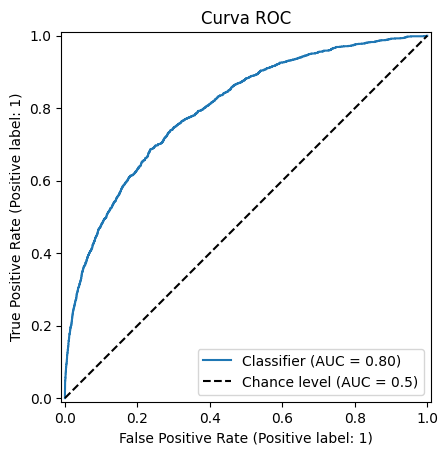

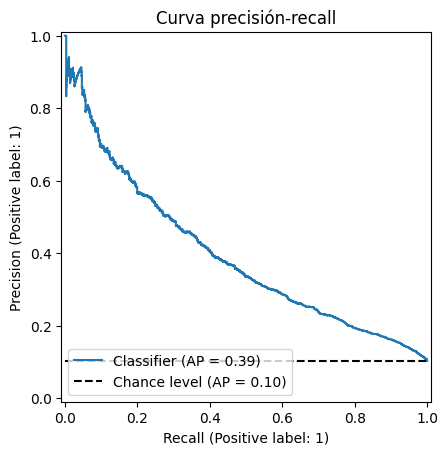

   probabilidad  abandono
0      0.085861         0
1      0.135857         0
2      0.426809         0
3      0.735881         0
4      0.175128         1


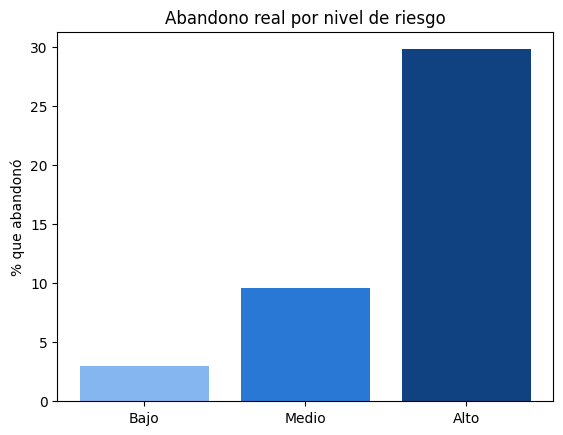

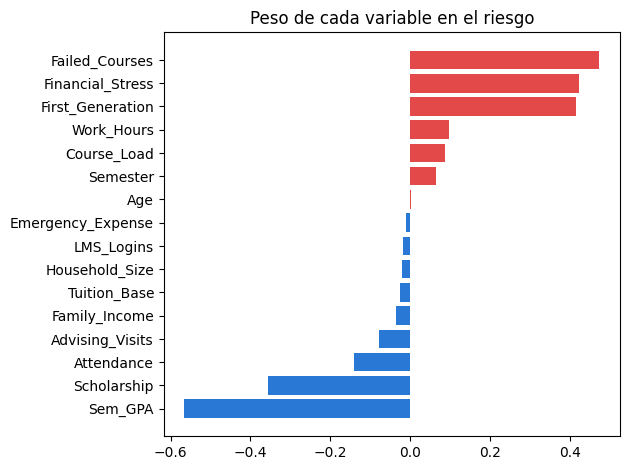

In [19]:
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

# 5) Evaluar Riesgo de abandono de cada estudiante de prueba (un número entre 0 y 1)
probabilidades = modelo.predict_proba(X.iloc[te])[:, 1]
print("ROC-AUC:", round(roc_auc_score(y.iloc[te], probabilidades), 3))   # el modelo le asigna más riesgo al que abandonó en el ROCU_AUC de los casos.
print("PR-AUC :", round(average_precision_score(y.iloc[te], probabilidades), 3), "| tasa base:", round(y.iloc[te].mean(), 3))


# Lo que pasó de verdad (1 = abandonó, 0 = no abandonó)
real = y.iloc[te]
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(real, probabilidades, plot_chance_level=True)
plt.title("Curva ROC")
plt.show()

from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(real, probabilidades, plot_chance_level=True)
plt.title("Curva precisión-recall")
plt.show()


# Armar una tabla con el riesgo y lo que pasó de verdad
tabla = pd.DataFrame({"probabilidad": probabilidades, "abandono": real.values})
print(tabla.head())

# Ordenar de mayor a menor riesgo
tabla = tabla.sort_values("probabilidad", ascending=False)

# Dividir en tres grupos
total = len(tabla)
alto  = tabla.iloc[0 : int(total * 0.20)]                  # 20% con más riesgo
medio = tabla.iloc[int(total * 0.20) : int(total * 0.50)]  # siguiente 30%
bajo  = tabla.iloc[int(total * 0.50) : ]                   # 50% restante

# Porcentaje que realmente abandonó en cada grupo
tasa_bajo  = bajo["abandono"].mean() * 100
tasa_medio = medio["abandono"].mean() * 100
tasa_alto  = alto["abandono"].mean() * 100

# Un color por cada barra, en el mismo orden: Bajo, Medio, Alto
colores = ["#86b6ef", "#2a78d6", "#104281"]

# Graficar
plt.bar(["Bajo", "Medio", "Alto"], [tasa_bajo, tasa_medio, tasa_alto] , color=colores)
plt.ylabel("% que abandonó")
plt.title("Abandono real por nivel de riesgo")
plt.show()


# 3) Variables que más pesan en el riesgo
colores = []
for valor in pesos.values:
    if valor > 0:
        colores.append("#e34948")   # rojo: sube el riesgo
    else:
        colores.append("#2a78d6")   # azul: baja el riesgo

plt.barh(pesos.index, pesos.values, color=colores)
plt.title("Peso de cada variable en el riesgo")
plt.tight_layout()
plt.show()



##🔹 Conclusión

El modelo ordena a los estudiantes por riesgo con una capacidad discriminativa buena (ROC-AUC 0.80) y rinde casi cuatro veces mejor que el azar para encontrar a quienes abandonan (PR-AUC 0.39 frente a 0.10). Sirve para priorizar a quién contactar, no para predecir con certeza el caso individual.

Los niveles de riesgo del modelo sí separan a quienes abandonan: en el grupo alto abandona casi 3 de cada 10 y en el bajo, 3 de cada 100.

Los factores que más se asocian con el abandono son los cursos reprobados, el estrés financiero y ser de primera generación; el GPA alto y la beca se asocian con menos riesgo.

**Limitaciones**
 El modelo estima riesgo, no causalidad, y no predice con certeza el caso individual Los resultados corresponden a un conjunto de prueba con estudiantes que el modelo no vio.

**Recomendaciones**
 Validar con datos de un semestre más reciente, revisar que el modelo funcione igual entre grupos (por ingreso o primera generación), probar variables de tendencia (cambio de GPA) y definir con la institución cuántos estudiantes se pueden contactar cada semestre.

##🔹 Comunicación de resultados - Power BI

🎯 Objetivo: Crear  dashboards que muestren de manera clara y visual los resultados del análisis anterior.

1. Preparación de los datos
- Cargar el  dataset_final_riesgo.csv
- Comprueba que cada columna tenga el tipo correcto (Power Query):
Texto: Student_ID, Gender_limpio, Housing_Status, End_of_Semester_Status, risk_tier, conjunto.
Número entero: Semester, Target_Dropout_Next_Sem, Censored, Scholarship, First_Generation.
Número decimal: risk_score, Sem_GPA, Attendance, Financial_Stress.
2. Crear columnas de apoyo y modelado DAX
3. Dashboards

1️⃣: Overview Ejecutivo KPIs principales a mostrar:

Estudiantes <br>
Inscritos al día de hoy <br>
Abandono   <br>
% Abandono   <br>
Graduados    <br>
% Graduados    <br>
% Riesgo de abandono   <br>
Gráfico de barras - Riesgo de abandono por semestre
Gráfico pie - Distribución de Estudiantes por Estatus Académico

2️⃣: Factores de Abandono
Riesgo de Abandono asociado a Beca
Riesgo de abandono asociado a cursos No aprobados
Riesgo de abandono asociado por Género
Riesgo de abandono asociaco a Tipo de residencia
Segmentadores por Beca, Cantidad de cursos no aprogados, género y tipo de residencia.

 3️⃣ : Estudiantes a priorizar
 KPI
 Alumnos en riesgo alto hoy
 Gráfico de barra- Clasificación de riesgo abandono
 Tabla con los 50 principales alumnos en riesgo de abandono











